# Particle Image Velocimetry

## 1. Problem

Recover both components of apparent planar tracer velocity at 70 fixed image locations from two repository-provided particle frames. Finite-window correspondence, repeated particles, intensity changes and fractional-pixel peaks make the inverse ambiguous. Instrument provenance is incomplete, so this review does not infer SI flow speed or independently measured fluid truth.

Save `output/reconstruction.npz` with real float64 `reconstruction` (1,7,10,2), component order (rightward u, downward v), in pixel/frame interval, and `confidence` (1,7,10), dimensionless peak-to-second-peak ratio. All values must be finite and every required metric must pass, with no fitted scale, sign or registration. This task selects OpenPIV's raw extended-search correlation stage; tutorial outlier interpolation, illustrative SI scaling and axis reversal are explicitly outside its bound contract.

## 2. Data

The two observations are `openpiv/data/test1/exp1_001_a.bmp` and `exp1_001_b.bmp` from [OpenPIV](https://github.com/OpenPIV/openpiv-python), immutable commit `91e88a8ee9289d6c4ca79722d9759c5258abd31d`. Both complete `(369,511)` monochrome images were decoded without cropping, resampling or color conversion and stored as batch-first uint8. The local loader promotes exact counts to float64. Although the repository calls the demonstration real PIV, independent experiment identity, camera length calibration and elapsed seconds are absent. Conflicting tutorial timing/scaling examples are not calibration for these observations: the selected interval is one frame interval, with x right and y down. There is no synthetic target or independently measured velocity truth.

The two images are supplied particle-image examples from the OpenPIV software distribution, preserved without resizing or generated blur. The distribution calls its example a real PIV demonstration, but it does not establish the apparatus, original acquisition date or calibrated physical frame spacing. Treat these as repository-provided observations with incomplete experimental provenance.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| frame_a | (1, 369, 511) | uint8 | First monochrome particle image, digital counts from 0 to 255; axes batch, row, column. |
| frame_b | (1, 369, 511) | uint8 | Second monochrome particle image, digital counts from 0 to 255; axes batch, row, column. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Image origin | top left | pixel | x is column, y is row; both positive toward increasing array index. |
| Spatial calibration | 1 | image pixel/pixel | No physical length calibration is available. |
| Frame spacing | 1 | frame interval | Relative timing convention; elapsed seconds are unavailable. |
| Search support | 64 by 64 | pixel | Fixed neighborhood defining each output location and correlation support. |
| Interrogation support | 32 by 32 | pixel | Central square of frame A in the 64-square neighborhood. |
| Neighbor overlap | 16 | pixel | Search windows overlap by this amount, giving grid step 48. |
| Grid x centers | 32 + 48 j, j=0,...,9 | pixel | Centers of actual extracted windows, without shifting the image or recentering unused margins. |
| Grid y centers | 32 + 48 i, i=0,...,6 | pixel | Centers of actual extracted windows. |
| Intensity response | stored digital counts | count | No radiometric calibration or sensor-noise distribution is supplied. |
| Boundary convention | circular within each 64-square map | pixel | Periodic correlation; no image-edge padding; unmatched trailing margins are unused. |
| Confidence exclusion | square half-width 2 | correlation pixel | Exclude the 5 by 5 neighborhood centered on the first peak when finding the second. |
| Peak stability offset | 0.0000001 | normalized correlation | Added to each correlation map after finding an interior peak, before subpixel fitting and confidence measurement. |

The confidence observable is the maximum correlation divided by the largest correlation outside the exclusion square. An edge maximum or first-peak height below 0.001 has confidence zero. A zero second peak, or a second peak on the edge whose height exceeds half the first, also yields zero. These conventions define the requested auxiliary quantity, not a calibrated probability of correctness.

The following cell actively loads the visible arrays. Hidden standard-method results are loaded only later for identified scientific comparisons; no target-derived calibration is supplied.

In [1]:
from pathlib import Path
import sys, time, json, subprocess
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root / 'data/raw_data.npz').exists():
    root = root.parent
assert (root / 'data/raw_data.npz').exists()
sys.path.insert(0, str(root))
from src.preprocessing import load_frames
from src.solvers import solve
from src.visualization import compare
a,b = load_frames(root/'data/raw_data.npz')
print('Bound frames:', a.shape, b.shape, 'pixel intensity counts')
with np.load(root/'data/raw_data.npz',allow_pickle=False) as visible:
    for key in visible.files:
        print(key,visible[key].shape,visible[key].dtype)

Bound frames: (369, 511) (369, 511) pixel intensity counts
frame_a (1, 369, 511) uint8
frame_b (1, 369, 511) uint8


## 3. Physics

For image position $r=(x,y)$, local tracer displacement $d$ obeys $B(r)\simeq A(r-d)+\eta(r)$ and $v=d/\Delta t$. A and B are grayscale digital counts, eta includes noise, intensity changes and particles entering/leaving; Delta t=1 frame interval because seconds are unavailable. The image origin is top left, x right/y down; projected motion is not out-of-plane flow.

The finite support model treats each extracted 64-square search neighborhood periodically for correlation; the central first-frame interrogation support is32 square. The search stride48 yields seven rows and ten columns; centers are (32+48j,32+48i), i=0..6,j=0..9, without recentering or padding. Trailing margins are unused. The local-translation approximation is limited by shear and particle decorrelation; no global intensity residual is claimed to have calibrated noise statistics.

## 4. Method

Search squares have side $S=64$, stride 48; the central first-frame interrogation
square has side 32. Define $N(W)$ as per-window population standardization and $M$
as the central support mask. Compute $A_1=N(M N(A))$ and $B_1=N(N(B))$, then

$$C=\operatorname{fftshift}\mathcal F^{-1}
[\overline{\mathcal F(A_1)}\mathcal F(B_1)]/S^2.$$

The DFT has circular window boundaries. Subtract $(32,32)$ from a correlation
peak's row/column position and exchange axes to obtain $(u,v)$. Three-point
Gaussian interpolation refines subpixel position; a negative fitted intensity
uses a parabolic fit. The original estimator adds $10^{-7}$ to a valid map before
fitting and confidence calculation. Confidence divides the highest peak by the
highest outside a 5-square exclusion neighborhood, with documented edge rejection.
No iterative optimization or training is involved.

Initialization and iterative stopping do not apply to this direct estimator. Each search-window pair is normalized, the first is centrally masked, and both are normalized again before the FFT. The first row-major maximum selects the peak. Gaussian log-denominator zero returns zero correction; an edge peak is invalid and causes solve to reject nonfinite velocity. Confidence half-width2, minimum peak0.001, epsilon1e-7, dt1 are fixed; no outlier interpolation, regularizer, training or line search is applied.

## 5. Results

All fresh results below are actively reconstructed with the shipped local modules. Archived upstream arrays remain explicitly identified comparison measurements, never measured truth or a replacement for computation.

Fresh local reconstruction: 0.018717 s
Velocity shape: (1, 7, 10, 2) confidence shape: (1, 7, 10)


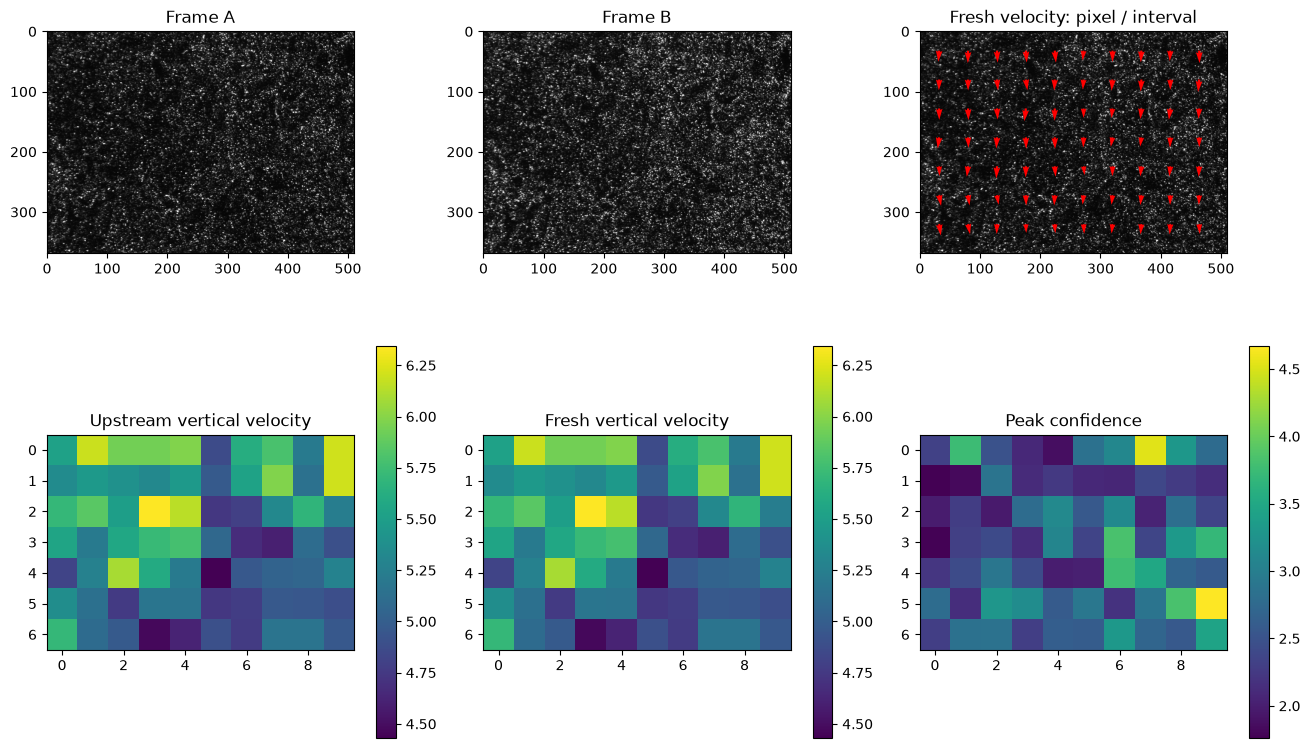

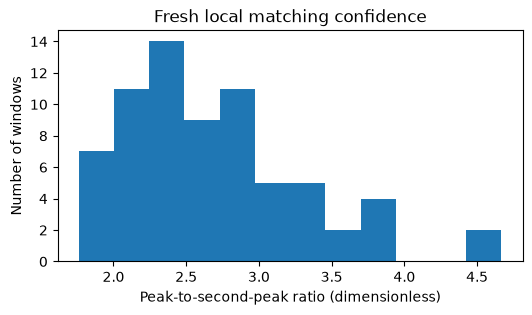

In [2]:
start = time.perf_counter()
velocity, confidence = solve(a,b)
runtime = time.perf_counter()-start
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz', reconstruction=velocity, confidence=confidence)
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as data:
    upstream = {k:data[k] for k in data.files}
print(f'Fresh local reconstruction: {runtime:.6f} s')
print('Velocity shape:',velocity.shape,'confidence shape:',confidence.shape)
fig = compare(a,b,velocity,upstream['reconstruction'],confidence)
plt.show()
fig,ax=plt.subplots(figsize=(6,3))
ax.hist(confidence.ravel(),bins=12)
ax.set_xlabel('Peak-to-second-peak ratio (dimensionless)')
ax.set_ylabel('Number of windows')
ax.set_title('Fresh local matching confidence')
plt.show()

### Independent upstream comparison and evaluation

The archived upstream array below was computed by an actual unmodified standard
method run on the exact packaged images. It is a **method baseline**, never
relabeled as physical truth. The fresh local result above is computed during
this notebook execution. Historical published accuracy numbers are not reused.
NCC is cosine similarity without centering; NRMSE is RMS error divided by the
range of the reference across both signed velocity components. Confidence uses
relative L2 error. There is no spatial, sign, intensity or phase alignment.

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0,
    "nrmse": 0.0,
    "confidence_relative_l2": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.99999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-08
    },
    "confidence_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-08
    }
  },
  "errors": []
}


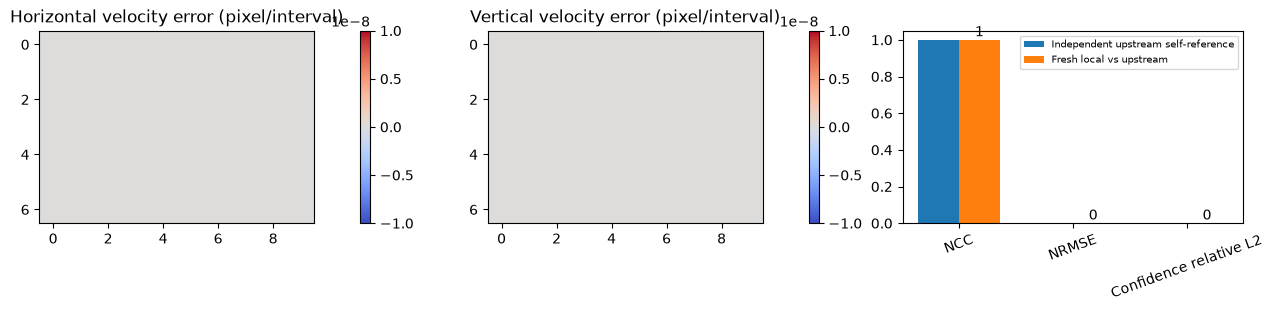

273

In [3]:
run = subprocess.run([sys.executable,str(root/'evaluation/judge.py'),
    '--prediction',str(root/'output/reconstruction.npz'),'--report',str(root/'output/judge_report.json')],
    cwd=root,capture_output=True,text=True)
assert run.returncode == 0, run.stdout+run.stderr
report=json.loads((root/'output/judge_report.json').read_text())
print(json.dumps(report,indent=2))
metrics=report['metrics']
residual=velocity-upstream['reconstruction']
fig,axs=plt.subplots(1,3,figsize=(13,3),constrained_layout=True)
for c,title in enumerate(['Horizontal velocity error (pixel/interval)','Vertical velocity error (pixel/interval)']):
    im=axs[c].imshow(residual[0,...,c],cmap='coolwarm',vmin=-1e-8,vmax=1e-8)
    fig.colorbar(im,ax=axs[c]);axs[c].set_title(title)
labels=['NCC','NRMSE','Confidence relative L2']
x=np.arange(3)
axs[2].bar(x-.18,[1,0,0],width=.36,label='Independent upstream self-reference')
axs[2].bar(x+.18,[metrics['ncc'],metrics['nrmse'],metrics['confidence_relative_l2']],width=.36,label='Fresh local vs upstream')
axs[2].set_xticks(x,labels,rotation=20);axs[2].legend(fontsize=7)
for j,val in enumerate([metrics['ncc'],metrics['nrmse'],metrics['confidence_relative_l2']]):
    axs[2].text(j+.18,val+.02,f'{val:.3g}',ha='center')
plt.show()
measurements={'source':'fresh actively executed cleaned modules','runtime_seconds':runtime,
    'metrics':metrics,'data_sha256':__import__('hashlib').sha256((root/'data/raw_data.npz').read_bytes()).hexdigest()}
(root/'notebooks/reference_outputs/cleaned_measurements.json').write_text(json.dumps(measurements,indent=2),encoding='utf-8')

## 6. Conclusion

The two-component field shows primarily downward tracer transport with smaller
horizontal motion. Independent upstream and fresh local values agree to the
frozen numerical tolerance. Confidence varies with local particle matching;
it is not a probability or physical uncertainty. Independent direct-sum
correlation, periodic known translations and analytic peak tests validate the
mathematical conventions. Agreement with a standard method establishes extraction
parity, while incomplete instrument provenance prevents claims of absolute
physical accuracy or calibrated flow velocity.